# 03 · Results and error analysis

Everything here is read from files that `txncat report` (M5) and `txncat errors` (M6) wrote to `reports/`; no
database, model or network is needed. Rerun those two commands, then this notebook, to refresh it.

In [1]:
import json
from pathlib import Path

import pandas as pd
from IPython.display import Image, display

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sig = json.loads((ROOT / "reports/metrics/significance.json").read_text())
err = json.loads((ROOT / "reports/metrics/error_analysis.json").read_text())
print("report:", sig["command"], sig["commit"], "| errors:", err["command"], err["commit"])

report: txncat report b29dd97 | errors: txncat errors 2f8e15a


## 1. Macro-F1 with 95% bootstrap CIs

Test = unseen synthetic merchants; external = independent dataset (DoDataThings v2). E3 is the mean of 3 seeds.

In [2]:
rows = []
for split in ("test", "external_test"):
    for model, e in sig["scores"][split].items():
        v = e["variants"]
        rows.append(
            {
                "split": split,
                "model": model,
                "macro_f1": e.get("mean_macro_f1", v[0]["macro_f1"]),
                "ci_low": min(x["ci95"][0] for x in v),
                "ci_high": max(x["ci95"][1] for x in v),
                "accuracy": sum(x["accuracy"] for x in v) / len(v),
            }
        )
scores = pd.DataFrame(rows).pivot(index="model", columns="split", values=["macro_f1", "ci_low", "ci_high"]).round(3)
scores

macro_f1               ci_low              ci_high       
split    external_test   test external_test   test external_test   test
model                                                                  
E0_rules         0.525  0.666         0.508  0.649         0.543  0.681
E1               0.576  0.839         0.556  0.825         0.595  0.852
E2               0.364  0.875         0.349  0.863         0.380  0.886
E3               0.613  0.850         0.587  0.817         0.639  0.873
E4               0.644  0.608         0.627  0.591         0.659  0.624
E5               0.667  0.670         0.649  0.653         0.685  0.686

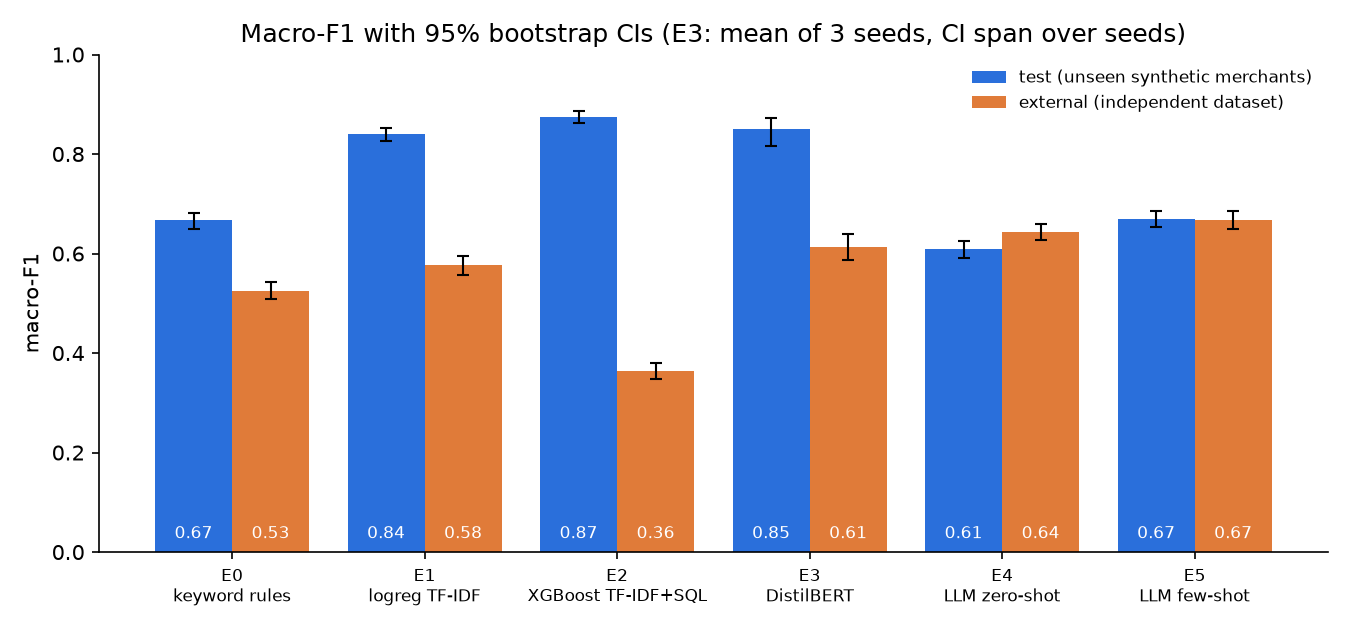

In [3]:
display(Image(ROOT / "reports/figures/f1_ci.png"))

## 2. Is the difference real? McNemar (exact) with Holm correction

For pairs with E3 every seed is tested; the pair counts only if all 3 seeds agree.

In [4]:
pd.DataFrame(
    [
        {
            "split": split,
            "pair": f"{p['a']} vs {p['b']}",
            "max Holm p": f"{p['max_p_holm']:.2g}",
            "ΔF1 (A−B)": " / ".join(f"{t['macro_f1_diff']:+.3f}" for t in p["tests"]),
            "significant": p["significant"],
            "better": p["better"],
        }
        for split, pairs in sig["pairs"].items()
        for p in pairs
    ]
)

,split,pair,max Holm p,ΔF1 (A−B),significant,better
0,test,E2 vs E3,0.9,+0.016 / +0.043 / +0.015,False,NaN
1,test,E2 vs E5,1e-83,+0.205,True,E2
2,test,E3 vs E5,5.8e-42,+0.189 / +0.162 / +0.190,True,E3
3,test,E4 vs E5,2.9e-07,-0.061,True,E5
4,external_test,E2 vs E3,3.7e-62,-0.244 / -0.255 / -0.247,True,E3
5,external_test,E2 vs E5,5.4e-122,-0.303,True,E5
6,external_test,E3 vs E5,0.0012,-0.059 / -0.048 / -0.056,True,E5
7,external_test,E4 vs E5,0.9,-0.024,False,NaN


## 3. Cost and latency

All models run locally, so API cost is $0. Latency = one transaction per call.

In [5]:
pd.DataFrame(
    [
        {
            "model": m,
            "train_seconds": c.get("train_seconds"),
            "p50_ms": (c.get("latency") or {}).get("p50_ms"),
            "p95_ms": (c.get("latency") or {}).get("p95_ms"),
            "device": (c.get("latency") or {}).get("device"),
            "gpu_p50_ms": (c.get("latency_gpu") or {}).get("p50_ms"),
        }
        for m, c in sig["cost_latency"].items()
    ]
).round(2)

,model,train_seconds,p50_ms,p95_ms,device,gpu_p50_ms
0,E1,7.90,1.40,1.88,cpu,NaN
1,E2,631.80,4.79,5.71,cpu,NaN
2,E3,825.87,10.97,19.36,cpu,5.24
3,E4,0.00,192.55,289.17,NVIDIA GeForce RTX 4060 Laptop GPU,NaN
4,E5,0.00,189.80,290.57,NVIDIA GeForce RTX 4060 Laptop GPU,NaN


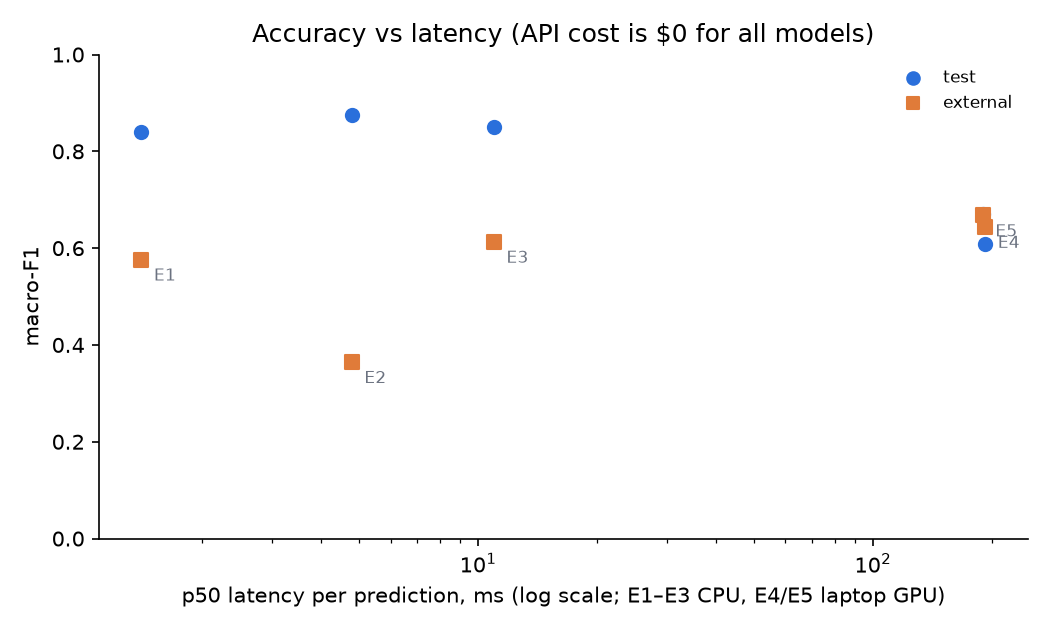

In [6]:
display(Image(ROOT / "reports/figures/latency_vs_f1.png"))

## 4. Error analysis of the best external model (E5, few-shot LLM)

Each E5 error gets one type from deterministic rules (`src/txncat/eval/errors.py`). The right-hand columns show what share of those rows each other model gets right.

In [7]:
types = {t["key"]: t["title"] for t in err["types"]}
table = pd.DataFrame(err["fixed_by"]).T.reindex(columns=["E1", "E2", "E3", "E4"])
table.insert(0, "E5 errors", pd.Series(err["counts"]))
table.index = [types[k] for k in table.index]
table.style.format({c: "{:.0%}" for c in ["E1", "E2", "E3", "E4"]})

,E5 errors,E1,E2,E3,E4
Invalid reply,136,47%,24%,33%,18%
Credit on an expense category,46,46%,0%,54%,46%
Taxonomy boundary (true 'Other'),115,28%,8%,31%,0%
Misread payment-rail text,58,33%,26%,56%,26%
Hedged to 'Other',361,40%,11%,43%,54%
Category confusion,36,36%,14%,58%,17%


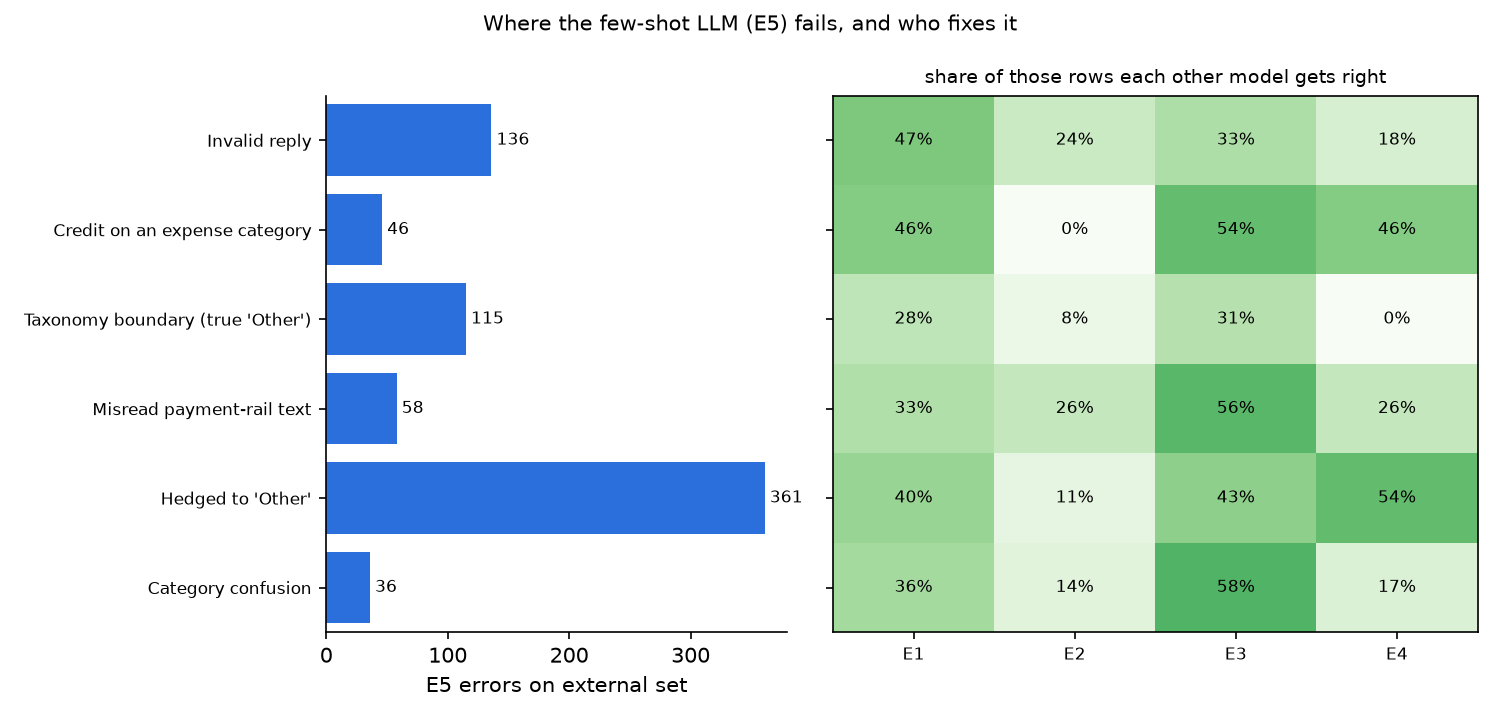

In [8]:
display(Image(ROOT / "reports/figures/error_types.png"))

### Few-shot examples push the LLM towards 'Other'

Share of rows whose true class is not Other that the LLM answers 'Other'.

In [9]:
pd.DataFrame(
    [
        {
            "split": s,
            "subset": k,
            "rows": d["E4"][k]["rows"],
            "E4 zero-shot": d["E4"][k]["share_answered_other"],
            "E5 few-shot": d["E5"][k]["share_answered_other"],
        }
        for s, d in err["other_overuse"].items()
        for k in ("pos_prefix", "no_prefix")
    ]
).style.format({"E4 zero-shot": "{:.1%}", "E5 few-shot": "{:.1%}"})

,split,subset,rows,E4 zero-shot,E5 few-shot
0,test,pos_prefix,186,0.0%,18.8%
1,test,no_prefix,2865,0.2%,2.9%
2,external_test,pos_prefix,51,0.0%,88.2%
3,external_test,no_prefix,1749,0.3%,18.1%


## 5. Takeaways

- On synthetic test data the trained models win; XGBoost and DistilBERT are statistically tied.
- On the independent external set the few-shot LLM is best, significantly better than every trained model.
- Its most common error (about half) is answering "Other" for a recognisable merchant, which the zero-shot prompt almost
  never does; it is strongly associated with Square/Toast-prefixed descriptions, matching one of its few-shot examples.
- The fine-tuned encoder (E3) gets most of the rows that trip the LLM on bank wording right, at ~5–11 ms per prediction.